# API 6: Training Hyperparamters

Regularization helps interpretability by making KANs sparser. This may require some hyperparamter tuning. Let's see how hyperparameters can affect training

Load KAN and create_dataset

In [1]:
import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

f = lambda x: torch.exp(torch.sin(torch.pi*x[:,[0]]) + x[:,[1]]**2)
train, test = create_dataset(f, n_var=2, device=device)
train['x'].shape, train['y'].shape

cuda


(torch.Size([1000, 2]), torch.Size([1000, 1]))

Default setup

train RMSE 0.051587598645370374 test RMSE 0.052629512265236454


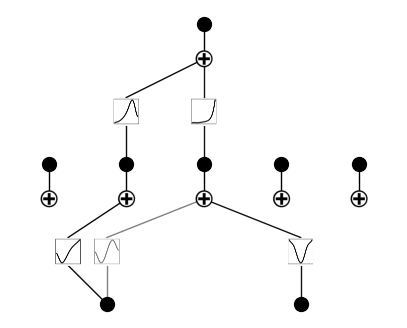

In [2]:
# train the model
model = KANNetwork([2,5,1], grid=5, k=3, seed=1, device=device)
history = fit(model, train, test, steps=20, lamb=0.01)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)
plot(model, train['x']);

### Parameter 1: $\lambda$, overall penalty strength. 

Previously $\lambda=0.01$, now we try different $\lambda$.

$\lambda=0$

train RMSE 0.005576276850735241 test RMSE 0.005895672010810739


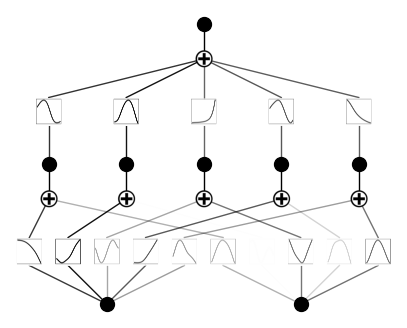

In [3]:
# train the model
model = KANNetwork([2,5,1], grid=5, k=3, seed=1, device=device)
history = fit(model, train, test, steps=20, lamb=0.00)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)
plot(model, train['x']);

$\lambda=1$

train RMSE 1.3676298897128203 test RMSE 1.396577973330213


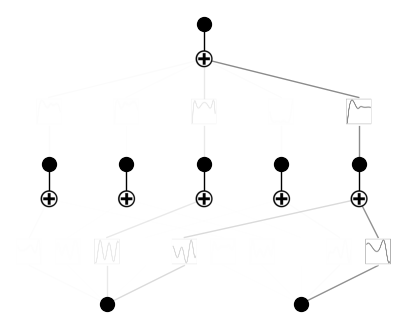

In [4]:
# train the model
model = KANNetwork([2,5,1], grid=5, k=3, seed=0, device=device)
history = fit(model, train, test, steps=20, lamb=1.0)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)
plot(model, train['x']);

### Parameter 2: (relative) penalty strength of entropy $\lambda_{\rm ent}$.

The absolute magnitude is $\lambda\lambda_{\rm ent}$. Previously we set $\lambda=0.1$ and $\lambda_{\rm ent}=2.0$ (default). Below we fix $\lambda=0.1$ and vary $\lambda_{\rm ent}$.

$\lambda_{\rm ent}=0.0$

train RMSE 0.03881369268808528 test RMSE 0.04505531560368396


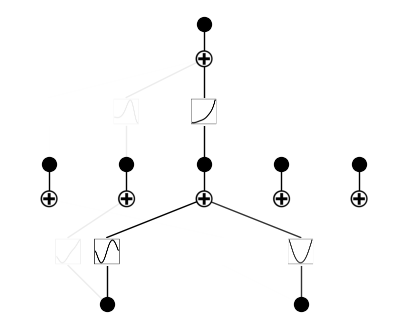

In [5]:
# train the model
model = KANNetwork([2,5,1], grid=5, k=3, seed=1, device=device)
history = fit(model, train, test, steps=20, lamb=0.01, lamb_entropy=0.0)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)
plot(model, train['x']);

$\lambda_{\rm ent}=10.$

train RMSE 0.07009241973670785 test RMSE 0.0707824354409323


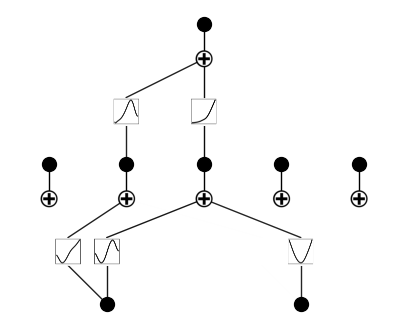

In [6]:
# train the model
model = KANNetwork([2,5,1], grid=5, k=3, seed=1, device=device)
history = fit(model, train, test, steps=20, lamb=0.01, lamb_entropy=10.0)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)
plot(model, train['x']);

### Parameter 3: seed. 

Previously we use seed = 1. Below we vary seed.

${\rm seed} = 42$

train RMSE 0.04908376530514943 test RMSE 0.04528535850105935


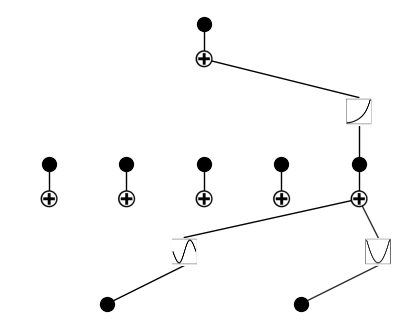

In [7]:
model = KANNetwork([2,5,1], grid=3, k=3, seed=42, device=device)
history = fit(model, train, test, steps=20, lamb=0.01)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)
plot(model, train['x']);